#  TP6 — Réseaux Récurrents : RNN, LSTM & LSTM Bidirectionnel
## Prédiction de Séries Temporelles — Dataset Jena Climate

**Module :** Deep Learning & Reinforcement Learning  
**Filière :** IITE-2  

---
###  Objectifs :
- Mettre en pratique RNN, LSTM et LSTM Bidirectionnel
- Comprendre les dépendances temporelles
- Implémenter des modèles **many-to-many** pour la prédiction multi-horizon
- Comparer les performances avec MAE, RMSE, R²
---

##  Étape 1 — Importation des bibliothèques

In [1]:
# Calcul numérique
import numpy as np
# Manipulation de tableaux / DataFrame
import pandas as pd
# Visualisation
import matplotlib.pyplot as plt
# Outils système pour gérer le chemin du fichier
import os
# Pour extraire le fichier ZIP
import zipfile
# Prétraitement
from sklearn.preprocessing import MinMaxScaler
# Métriques
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
# Modèles Keras
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import SimpleRNN, LSTM, GRU, Dense, Bidirectional
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.utils import get_file

print('✅ Bibliothèques importées avec succès !')

✅ Bibliothèques importées avec succès !


---
##  PARTIE I — Questions Q1 à Q10
---

## Q1) Chargement du Dataset Jena Climate

In [2]:
# URL officielle du dataset Jena Climate au format ZIP
url = 'https://storage.googleapis.com/tensorflow/tf-keras-datasets/jena_climate_2009_2016.csv.zip'

# Télécharger le ZIP
zip_path = get_file(
    fname='jena_climate_2009_2016.csv.zip',
    origin=url,
    extract=False
)

# Dossier où le ZIP a été téléchargé
extract_dir = os.path.dirname(zip_path)

# Extraire le contenu du ZIP
with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_dir)

# Chemin du CSV extrait
csv_path = os.path.join(extract_dir, 'jena_climate_2009_2016.csv')

# Lire le CSV
df = pd.read_csv(csv_path)

# Affichage des 5 premières lignes
print('=== 5 PREMIÈRES LIGNES DU DATASET ===')
print(df.head())

# Taille du dataset
print('\n=== TAILLE DU DATASET ===')
print('Shape du DataFrame :', df.shape)

# Noms des colonnes
print('\n=== NOMS DES COLONNES ===')
print(df.columns.tolist())

13568290/13568290 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
=== 5 PREMIÈRES LIGNES DU DATASET ===
             Date Time  p (mbar)  T (degC)  Tpot (K)  Tdew (degC)  rh (%)  \
0  01.01.2009 00:10:00    996.52     -8.02    265.40        -8.90    93.3   
1  01.01.2009 00:20:00    996.57     -8.41    265.01        -9.28    93.4   
2  01.01.2009 00:30:00    996.53     -8.51    264.91        -9.31    93.9   
3  01.01.2009 00:40:00    996.51     -8.31    265.12        -9.07    94.2   
4  01.01.2009 00:50:00    996.51     -8.27    265.15        -9.04    94.1   

   VPmax (mbar)  VPact (mbar)  VPdef (mbar)  sh (g/kg)  H2OC (mmol/mol)  \
0          3.33          3.11          0.22       1.94             3.12   
1          3.23          3.02          0.21       1.89             3.03   
2          3.21          3.01          0.20       1.88             3.02   
3          3.26          3.07          0.19       1.92             3.08   
4          3.27          3.08          0.19       1.92             3.09  

**Réponse Q1 :**
> Le dataset Jena Climate contient **420 551 lignes** et **15 colonnes** (1 colonne Date Time + 14 variables météorologiques). Les mesures sont prises **toutes les 10 minutes** de 2009 à 2016 depuis une station météorologique en Allemagne.

## Q2) Extraction de la variable cible T (degC)

In [3]:
# On garde uniquement la température
data = df['T (degC)'].values.reshape(-1, 1)

# Vérification
print('Shape de la série univariée :', data.shape)

Shape de la série univariée : (420551, 1)


** Réponse Q2 :**
> La dimension obtenue est **(420551, 1)**.
>
> On transforme les données en format **(n, 1)** car :
> - Le **MinMaxScaler** de scikit-learn attend un tableau 2D en entrée (n_samples × n_features)
> - Les couches RNN/LSTM de Keras attendent une entrée de forme **(batch_size, timesteps, features)** — le '1' correspond à 1 feature (série univariée)
> - Sans ce reshape, on aurait un vecteur 1D de forme (420551,) qui causerait des erreurs lors du scaling et de la création des séquences

## Q3) Division des données en respectant l'ordre temporel (70% / 15% / 15%)

In [4]:
# SPLIT TRAIN / VAL / TEST SANS SHUFFLE ET ENCHAÎNÉ DANS LE TEMPS
# Nombre total d'observations
n = len(data)

# 70% train, 15% validation, 15% test
train_size = int(n * 0.70)
val_size   = int(n * 0.15)

# Découpage chronologique (pas de mélange !)
train_data = data[:train_size]
val_data   = data[train_size : train_size + val_size]
test_data  = data[train_size + val_size:]

# Vérification
print('Train      :', train_data.shape)
print('Validation :', val_data.shape)
print('Test       :', test_data.shape)
print(f'Total = {len(train_data)+len(val_data)+len(test_data)} (original: {n})')

Train      : (294385, 1)
Validation : (63082, 1)
Test       : (63084, 1)
Total = 420551 (original: 420551)


## Q4) Normalisation avec MinMaxScaler

In [5]:
# Création du scaler
scaler = MinMaxScaler()

# On ajuste le scaler UNIQUEMENT sur le train
# (pour éviter la fuite d'information du futur)
train_scaled = scaler.fit_transform(train_data)

# On applique le MÊME scaler à val et test
val_scaled   = scaler.transform(val_data)
test_scaled  = scaler.transform(test_data)

# Vérification
print('Train scaled min/max :', train_scaled.min(), train_scaled.max())
print('Val   scaled min/max :', val_scaled.min().round(3), val_scaled.max().round(3))
print('Test  scaled min/max :', test_scaled.min().round(3), test_scaled.max().round(3))

Train scaled min/max : 0.0 1.0
Val   scaled min/max : 0.25 1.024
Test  scaled min/max : 0.154 0.974


## Q5) Implémentation de `create_sequences_multistep(data, lookback, horizon)`

In [6]:
def create_sequences_multistep(data, lookback, horizon):
    """
    Crée des séquences d'entrée/sortie pour la prédiction multi-horizon.

    Paramètres:
    -----------
    data     : tableau numpy de forme (n, 1)
    lookback : nombre de pas passés utilisés en entrée
    horizon  : nombre de pas futurs à prédire

    Retourne:
    ---------
    X : (n_samples, lookback, 1)  — fenêtres d'entrée
    y : (n_samples, horizon)      — valeurs futures à prédire
    """
    X = []
    y = []
    # On parcourt la série
    for i in range(len(data) - lookback - horizon + 1):
        # Fenêtre passée
        x_seq = data[i : i + lookback]
        # Les valeurs futures à prédire
        y_seq = data[i + lookback : i + lookback + horizon]
        # Ajouter la fenêtre d'entrée
        X.append(x_seq)
        # Ajouter les sorties futures aplaties
        y.append(y_seq.flatten())
    # Convertir en tableaux numpy
    X = np.array(X)
    y = np.array(y)
    return X, y

# Nombre de pas passés utilisés en entrée (72 mesures = 12h à 10min/mesure)
lookback = 72
# Nombre de pas futurs à prédire : t+1 à t+10
horizon  = 10

# Création des séquences
X_train, y_train = create_sequences_multistep(train_scaled, lookback, horizon)
X_val,   y_val   = create_sequences_multistep(val_scaled,   lookback, horizon)
X_test,  y_test  = create_sequences_multistep(test_scaled,  lookback, horizon)

print('✅ Séquences créées avec lookback=72 (12h) et horizon=10 (1h40)')

✅ Séquences créées avec lookback=72 (12h) et horizon=10 (1h40)


## Q6) Dimensions de X_train et y_train — Interprétation

In [7]:
# Vérification des shapes
print('=== DIMENSIONS DES DONNÉES ===')
print('X_train :', X_train.shape)
print('y_train :', y_train.shape)
print('X_val   :', X_val.shape)
print('y_val   :', y_val.shape)
print('X_test  :', X_test.shape)
print('y_test  :', y_test.shape)

print('\n=== EXEMPLE X_train[0] (les 72 pas passés) ===')
print('Shape X_train[0] :', X_train[0].shape)
# Afficher quelques valeurs
print('5 premières valeurs :', X_train[0][:5].flatten().round(4))
print('5 dernières valeurs  :', X_train[0][-5:].flatten().round(4))

print('\n=== EXEMPLE y_train[0] (les 10 valeurs futures à prédire) ===')
print('Shape y_train[0] :', y_train[0].shape)
print('Valeurs :', y_train[0].round(4))

=== DIMENSIONS DES DONNÉES ===
X_train : (294304, 72, 1)
y_train : (294304, 10)
X_val   : (63001, 72, 1)
y_val   : (63001, 10)
X_test  : (63003, 72, 1)
y_test  : (63003, 10)

=== EXEMPLE X_train[0] (les 72 pas passés) ===
Shape X_train[0] : (72, 1)
5 premières valeurs : [0.2546 0.248  0.2463 0.2497 0.2504]
5 dernières valeurs  : [0.2655 0.2684 0.2692 0.2714 0.2742]

=== EXEMPLE y_train[0] (les 10 valeurs futures à prédire) ===
Shape y_train[0] : (10,)
Valeurs : [0.2759 0.2771 0.2786 0.2803 0.2854 0.2908 0.2918 0.293  0.2906 0.2895]


**✏️ Réponse Q6 :**

> **Dimensions de X_train :** `(n_sequences, 72, 1)`  
> Chaque ligne de X_train représente une **fenêtre temporelle de 72 pas** (= 12 heures de mesures à 10 min/mesure), avec 1 seule feature (température normalisée).
>
> **Dimensions de y_train :** `(n_sequences, 10)`  
> **Une ligne de y_train** représente les **10 prochaines valeurs de température** (normalisées) immédiatement après la fenêtre d'entrée correspondante. Autrement dit, si X_train[i] = [t-71, t-70, ..., t], alors y_train[i] = [t+1, t+2, ..., t+10]. C'est la cible que le modèle doit apprendre à prédire.
>
> **X_train[0]** : la première fenêtre d'observation, 72 valeurs de température normalisées de 0 à 1.  
> **y_train[0]** : les 10 températures futures correspondantes (t+1 à t+10), normalisées.

## Q7) Construction des modèles : SimpleRNN, LSTM, LSTM Bidirectionnel

In [8]:
# ─────────────────────────────────────────────
# Modèle 1 : SimpleRNN
# ─────────────────────────────────────────────
def build_rnn_model(lookback, horizon):
    model = Sequential()
    model.add(SimpleRNN(64, input_shape=(lookback, 1)))
    model.add(Dense(horizon))
    model.compile(optimizer='adam', loss='mse')
    return model

# ─────────────────────────────────────────────
# Modèle 2 : LSTM
# ─────────────────────────────────────────────
def build_lstm_model(lookback, horizon):
    model = Sequential()
    model.add(LSTM(64, input_shape=(lookback, 1)))
    model.add(Dense(horizon))
    model.compile(optimizer='adam', loss='mse')
    return model

# ─────────────────────────────────────────────
# Modèle 3 : LSTM Bidirectionnel
# (demandé dans l'énoncé à la place du GRU du cours)
# ─────────────────────────────────────────────
def build_bilstm_model(lookback, horizon):
    model = Sequential()
    model.add(Bidirectional(LSTM(64), input_shape=(lookback, 1)))
    model.add(Dense(horizon))
    model.compile(optimizer='adam', loss='mse')
    return model

# Construction des modèles
model_rnn    = build_rnn_model(lookback, horizon)
model_lstm   = build_lstm_model(lookback, horizon)
model_bilstm = build_bilstm_model(lookback, horizon)

# Résumés
print('=== SimpleRNN ===')
model_rnn.summary()
print('\n=== LSTM ===')
model_lstm.summary()
print('\n=== LSTM Bidirectionnel ===')
model_bilstm.summary()

# Early Stopping (patience=5, restore best weights)
early_stop = EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True
)

print('\n✅ Modèles construits avec :')
print('  - 64 neurones dans la couche récurrente')
print('  - Optimizer Adam, loss MSE')
print('  - 20 époques max, batch_size=64')
print('  - EarlyStopping patience=5')

=== SimpleRNN ===


/usr/local/lib/python3.12/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)
/usr/local/lib/python3.12/dist-packages/keras/src/layers/rnn/bidirectional.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ simple_rnn (SimpleRNN)          │ (None, 64)             │         4,224 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,874 (19.04 KB)

 Trainable params: 4,874 (19.04 KB)

... (10 outputs left out)

 Total params: 35,082 (137.04 KB)

 Trainable params: 35,082 (137.04 KB)

 Non-trainable params: 0 (0.00 B)


✅ Modèles construits avec :
  - 64 neurones dans la couche récurrente
  - Optimizer Adam, loss MSE
  - 20 époques max, batch_size=64
  - EarlyStopping patience=5


### Entraînement — SimpleRNN

In [9]:
# Entraînement RNN
history_rnn = model_rnn.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=20,
    batch_size=64,
    callbacks=[early_stop],
    verbose=1
)

Epoch 1/20
4599/4599 ━━━━━━━━━━━━━━━━━━━━ 75s 16ms/step - loss: 8.6507e-04 - val_loss: 2.5741e-04
Epoch 2/20
4599/4599 ━━━━━━━━━━━━━━━━━━━━ 82s 16ms/step - loss: 2.2545e-04 - val_loss: 2.0031e-04
Epoch 3/20
4599/4599 ━━━━━━━━━━━━━━━━━━━━ 71s 15ms/step - loss: 2.0375e-04 - val_loss: 1.9030e-04
Epoch 4/20
4599/4599 ━━━━━━━━━━━━━━━━━━━━ 81s 15ms/step - loss: 1.9227e-04 - val_loss: 1.9432e-04
Epoch 5/20
4599/4599 ━━━━━━━━━━━━━━━━━━━━ 76s 16ms/step - loss: 1.8731e-04 - val_loss: 1.9572e-04
Epoch 6/20
4599/4599 ━━━━━━━━━━━━━━━━━━━━ 76s 17ms/step - loss: 1.8678e-04 - val_loss: 1.8173e-04
Epoch 7/20
4599/4599 ━━━━━━━━━━━━━━━━━━━━ 78s 16ms/step - loss: 1.8797e-04 - val_loss: 2.0470e-04
Epoch 8/20
4599/4599 ━━━━━━━━━━━━━━━━━━━━ 71s 15ms/step - loss: 1.8744e-04 - val_loss: 1.8259e-04
Epoch 9/20
4599/4599 ━━━━━━━━━━━━━━━━━━━━ 83s 16ms/step - loss: 1.8938e-04 - val_loss: 1.8574e-04
Epoch 10/20
4599/4599 ━━━━━━━━━━━━━━━━━━━━ 72s 16ms/step - loss: 1.9958e-04 - val_loss: 2.1095e-04
Epoch 11/20
4599/45

### Entraînement — LSTM

In [10]:
# Entraînement LSTM
history_lstm = model_lstm.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=20,
    batch_size=64,
    callbacks=[early_stop],
    verbose=1
)

Epoch 1/20
4599/4599 ━━━━━━━━━━━━━━━━━━━━ 192s 41ms/step - loss: 0.0011 - val_loss: 2.4557e-04
Epoch 2/20
4599/4599 ━━━━━━━━━━━━━━━━━━━━ 184s 40ms/step - loss: 2.2869e-04 - val_loss: 2.0417e-04
Epoch 3/20
4599/4599 ━━━━━━━━━━━━━━━━━━━━ 183s 40ms/step - loss: 1.9690e-04 - val_loss: 1.8860e-04
Epoch 4/20
4599/4599 ━━━━━━━━━━━━━━━━━━━━ 208s 41ms/step - loss: 1.8197e-04 - val_loss: 1.8640e-04
Epoch 5/20
4599/4599 ━━━━━━━━━━━━━━━━━━━━ 199s 41ms/step - loss: 1.7384e-04 - val_loss: 1.7639e-04
Epoch 6/20
4599/4599 ━━━━━━━━━━━━━━━━━━━━ 188s 41ms/step - loss: 1.7070e-04 - val_loss: 1.7792e-04
Epoch 7/20
4599/4599 ━━━━━━━━━━━━━━━━━━━━ 197s 40ms/step - loss: 1.6919e-04 - val_loss: 1.7090e-04
Epoch 8/20
4599/4599 ━━━━━━━━━━━━━━━━━━━━ 188s 41ms/step - loss: 1.6789e-04 - val_loss: 1.8501e-04
Epoch 9/20
4599/4599 ━━━━━━━━━━━━━━━━━━━━ 186s 40ms/step - loss: 1.6653e-04 - val_loss: 1.7323e-04
Epoch 10/20
4599/4599 ━━━━━━━━━━━━━━━━━━━━ 184s 40ms/step - loss: 1.6562e-04 - val_loss: 1.6571e-04
Epoch 11/20
4

### Entraînement — LSTM Bidirectionnel

In [11]:
# Entraînement LSTM Bidirectionnel
history_bilstm = model_bilstm.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=20,
    batch_size=64,
    callbacks=[early_stop],
    verbose=1
)

Epoch 1/20
4599/4599 ━━━━━━━━━━━━━━━━━━━━ 320s 69ms/step - loss: 7.6644e-04 - val_loss: 2.4560e-04
Epoch 2/20
4599/4599 ━━━━━━━━━━━━━━━━━━━━ 315s 68ms/step - loss: 2.1399e-04 - val_loss: 1.9353e-04
Epoch 3/20
4599/4599 ━━━━━━━━━━━━━━━━━━━━ 323s 69ms/step - loss: 1.8633e-04 - val_loss: 1.8081e-04
Epoch 4/20
4599/4599 ━━━━━━━━━━━━━━━━━━━━ 315s 68ms/step - loss: 1.7671e-04 - val_loss: 1.9296e-04
Epoch 5/20
4599/4599 ━━━━━━━━━━━━━━━━━━━━ 329s 70ms/step - loss: 1.7319e-04 - val_loss: 1.7308e-04


## Q8) Courbes d'apprentissage (loss train et loss validation)

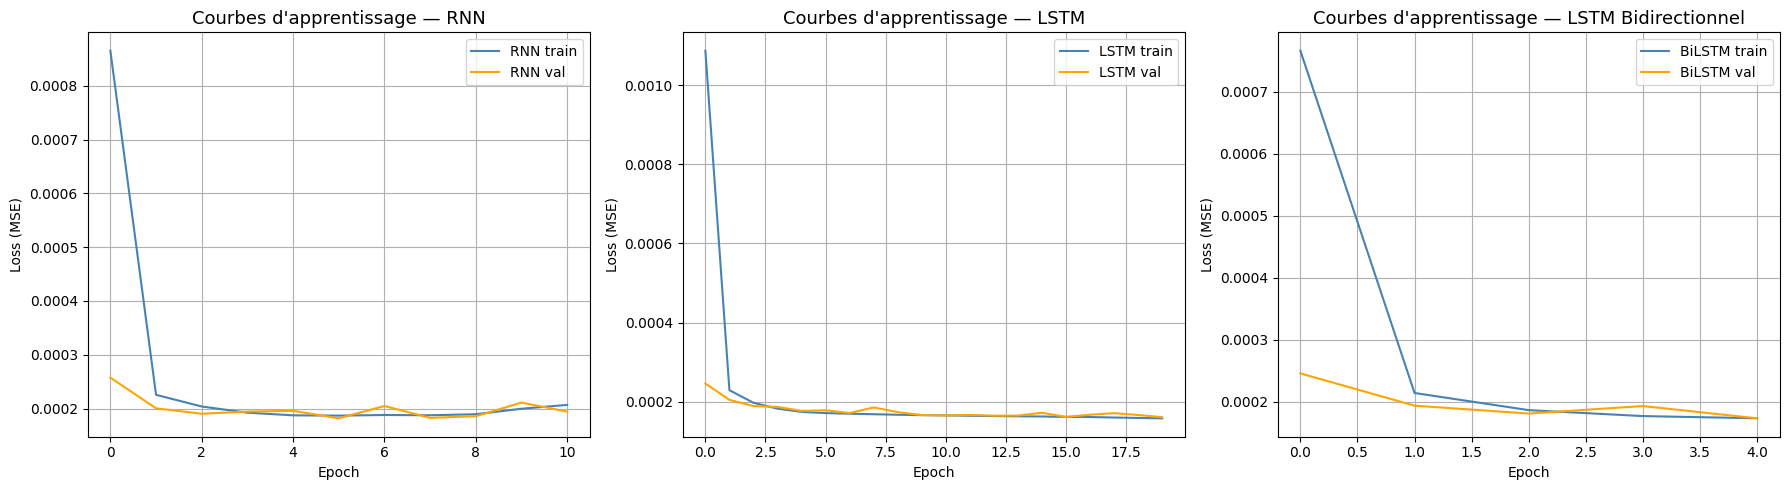

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# --- RNN ---
axes[0].plot(history_rnn.history['loss'],     label='RNN train', color='steelblue')
axes[0].plot(history_rnn.history['val_loss'], label='RNN val',   color='orange')
axes[0].set_title('Courbes d\'apprentissage — RNN', fontsize=13)
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Loss (MSE)')
axes[0].legend()
axes[0].grid(True)

# --- LSTM ---
axes[1].plot(history_lstm.history['loss'],     label='LSTM train', color='steelblue')
axes[1].plot(history_lstm.history['val_loss'], label='LSTM val',   color='orange')
axes[1].set_title('Courbes d\'apprentissage — LSTM', fontsize=13)
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Loss (MSE)')
axes[1].legend()
axes[1].grid(True)

# --- BiLSTM ---
axes[2].plot(history_bilstm.history['loss'],     label='BiLSTM train', color='steelblue')
axes[2].plot(history_bilstm.history['val_loss'], label='BiLSTM val',   color='orange')
axes[2].set_title('Courbes d\'apprentissage — LSTM Bidirectionnel', fontsize=13)
axes[2].set_xlabel('Epoch')
axes[2].set_ylabel('Loss (MSE)')
axes[2].legend()
axes[2].grid(True)

plt.tight_layout()
plt.show()

## Q9) Prédictions sur le test set, inverse scaling et métriques par horizon

In [13]:
# Prédictions (encore normalisées)
y_pred_rnn    = model_rnn.predict(X_test)
y_pred_lstm   = model_lstm.predict(X_test)
y_pred_bilstm = model_bilstm.predict(X_test)

print('Shape y_pred_rnn    :', y_pred_rnn.shape)
print('Shape y_pred_lstm   :', y_pred_lstm.shape)
print('Shape y_pred_bilstm :', y_pred_bilstm.shape)

1969/1969 ━━━━━━━━━━━━━━━━━━━━ 11s 6ms/step
1969/1969 ━━━━━━━━━━━━━━━━━━━━ 21s 11ms/step
1969/1969 ━━━━━━━━━━━━━━━━━━━━ 29s 15ms/step
Shape y_pred_rnn    : (63003, 10)
Shape y_pred_lstm   : (63003, 10)
Shape y_pred_bilstm : (63003, 10)


In [ ]:
# ─────────────────────────────────────────────
# Inverse scaling (retour à l'échelle originale °C)
# y_test est de forme (n_samples, horizon)
# scaler a été ajusté sur une seule variable -> inverse_transform direct
# ─────────────────────────────────────────────
y_test_inv        = scaler.inverse_transform(y_test)
y_pred_rnn_inv    = scaler.inverse_transform(y_pred_rnn)
y_pred_lstm_inv   = scaler.inverse_transform(y_pred_lstm)
y_pred_bilstm_inv = scaler.inverse_transform(y_pred_bilstm)

print('Exemple y_test_inv[0] (températures réelles en °C) :')
print(y_test_inv[0])

In [ ]:
def evaluate_multistep(y_true, y_pred, model_name='Modèle'):
    """
    Évalue le modèle par horizon (t+1 à t+10).
    Calcule MAE, RMSE et R² pour chaque horizon.
    """
    print(f'\n===== Évaluation de {model_name} =====')
    for h in range(y_true.shape[1]):
        true_h = y_true[:, h]
        pred_h = y_pred[:, h]

        mae  = mean_absolute_error(true_h, pred_h)
        rmse = np.sqrt(mean_squared_error(true_h, pred_h))
        r2   = r2_score(true_h, pred_h)

        print(f't+{h+1:02d} | MAE = {mae:.4f} | RMSE = {rmse:.4f} | R² = {r2:.4f}')

# Évaluation des trois modèles
evaluate_multistep(y_test_inv, y_pred_rnn_inv,    'RNN')
evaluate_multistep(y_test_inv, y_pred_lstm_inv,   'LSTM')
evaluate_multistep(y_test_inv, y_pred_bilstm_inv, 'LSTM Bidirectionnel')

## Q10) Visualisation des prédictions pour les horizons t+1 à t+10

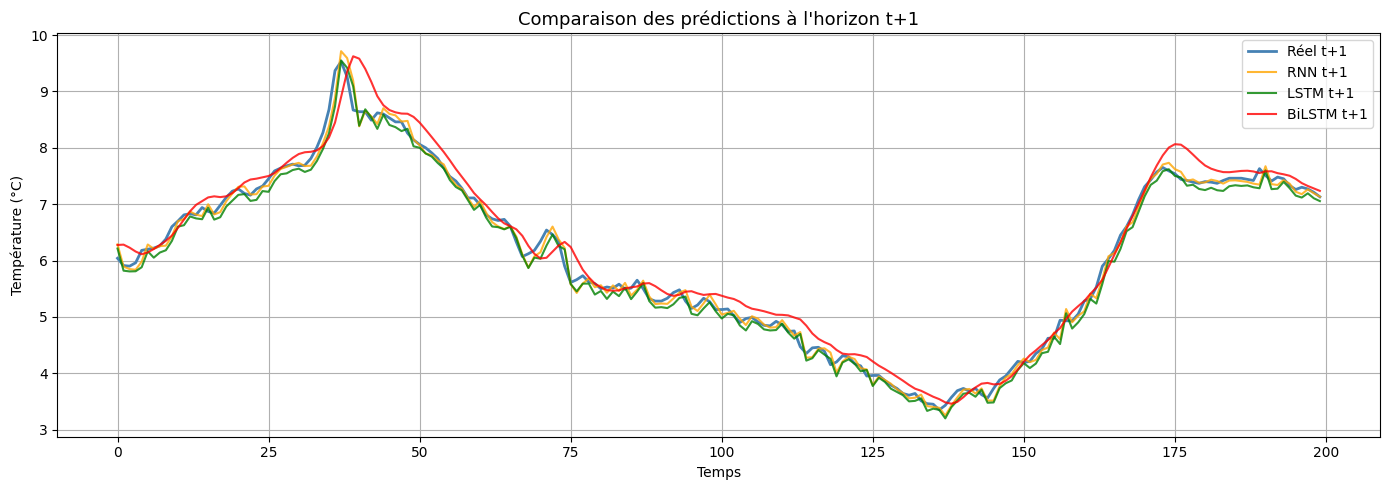

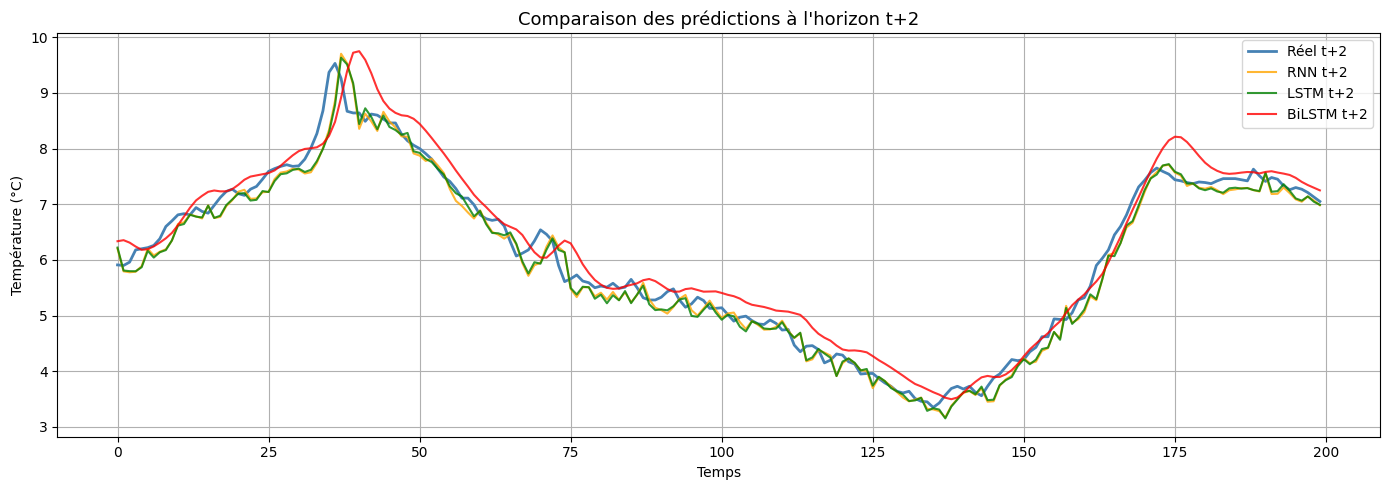

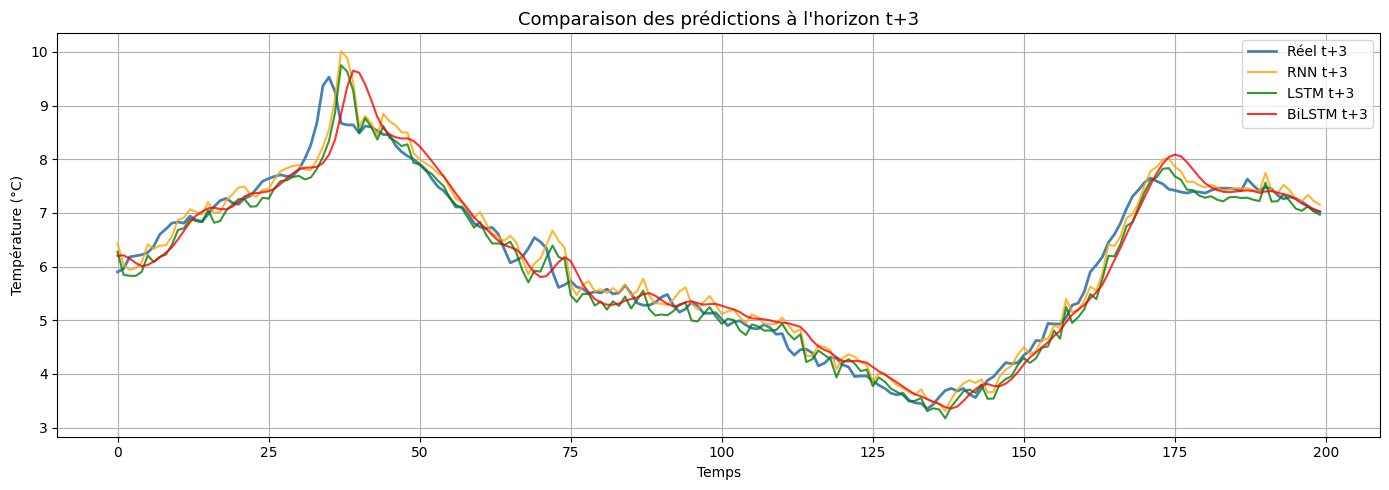

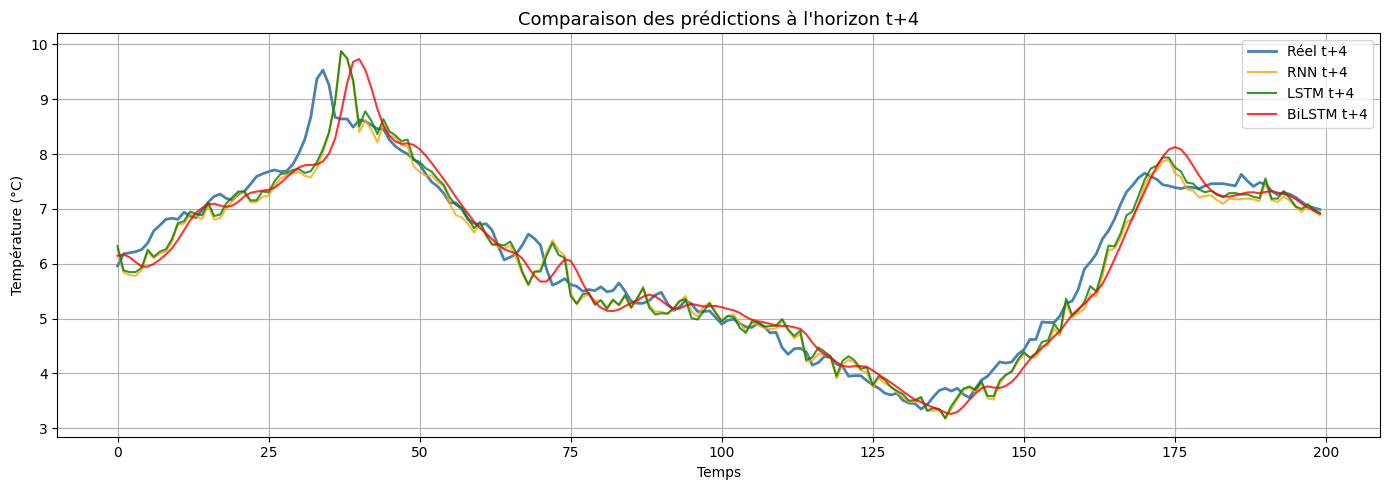

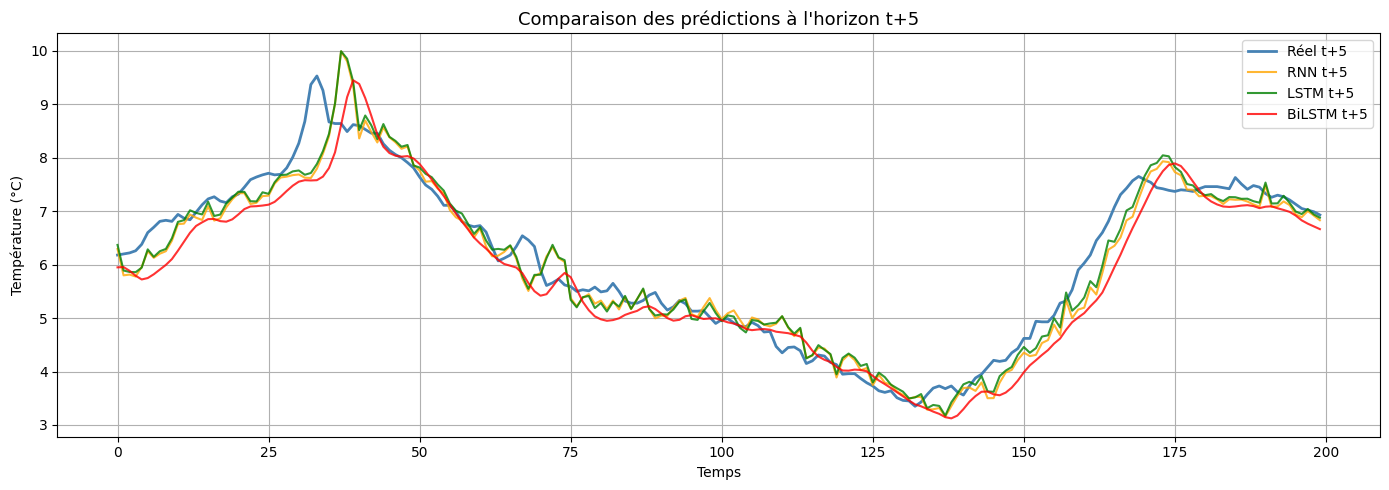

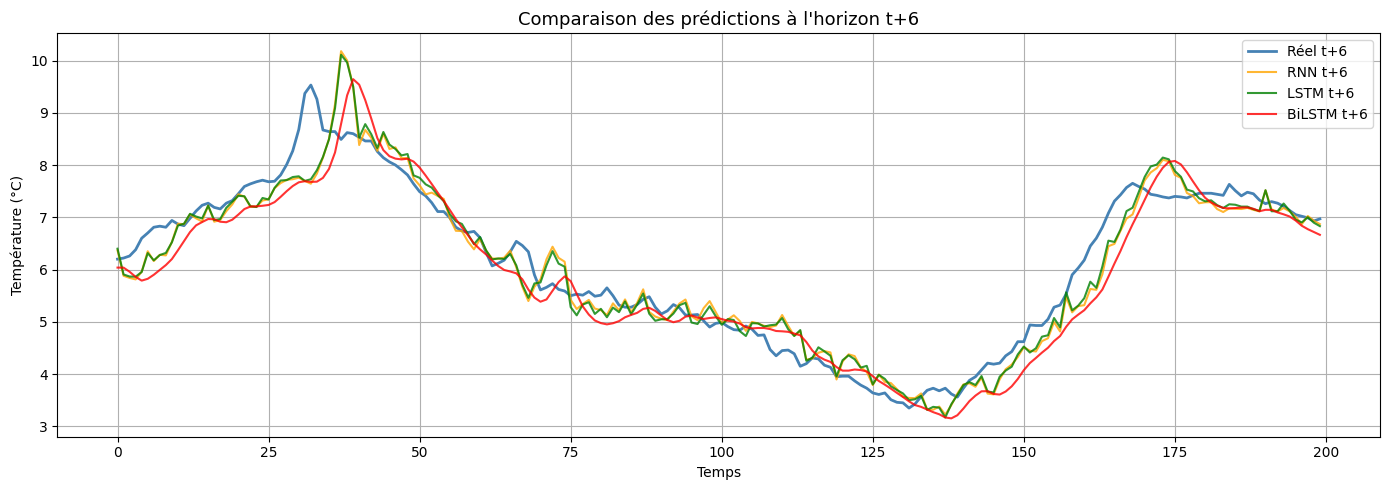

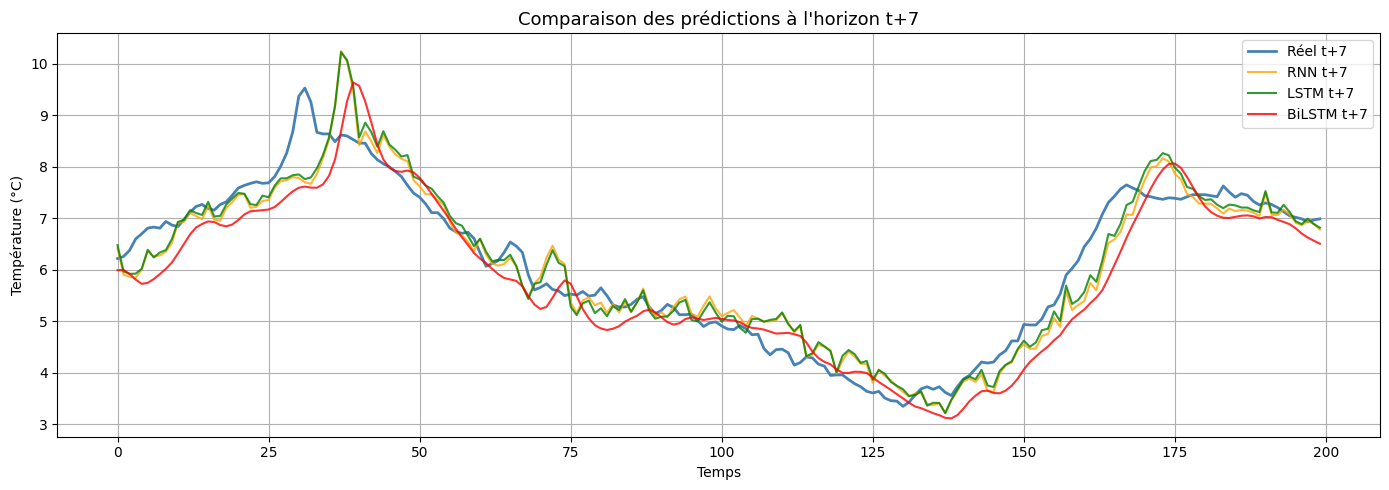

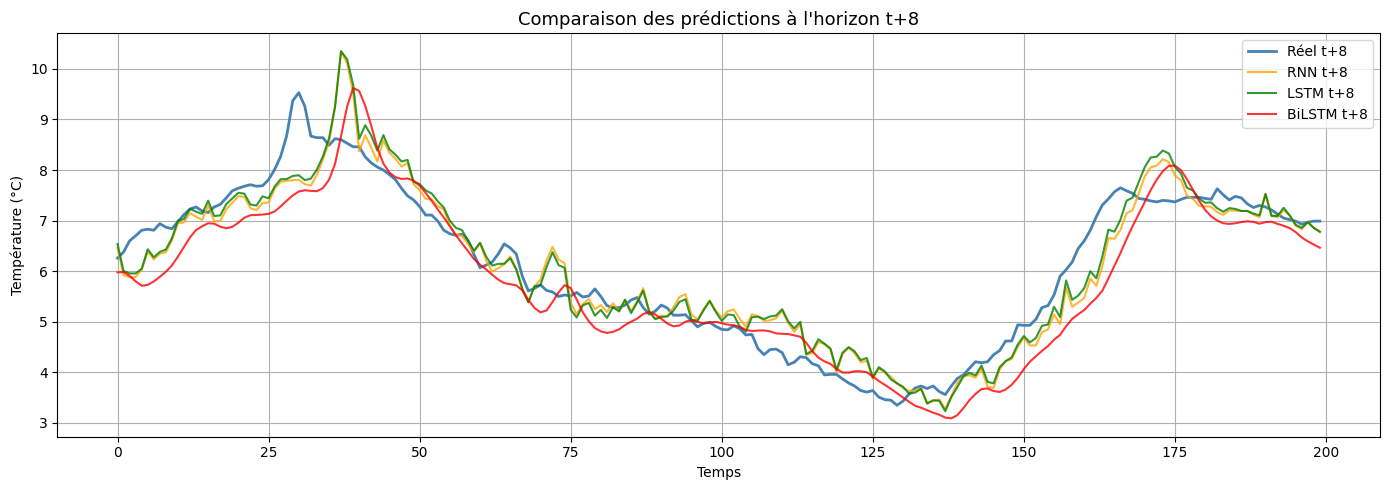

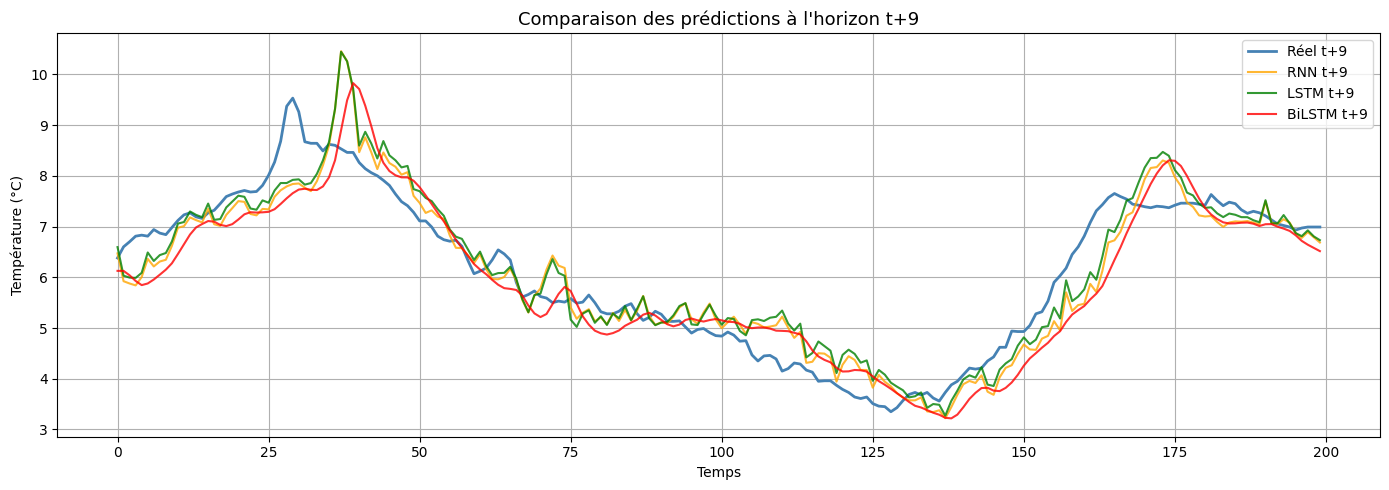

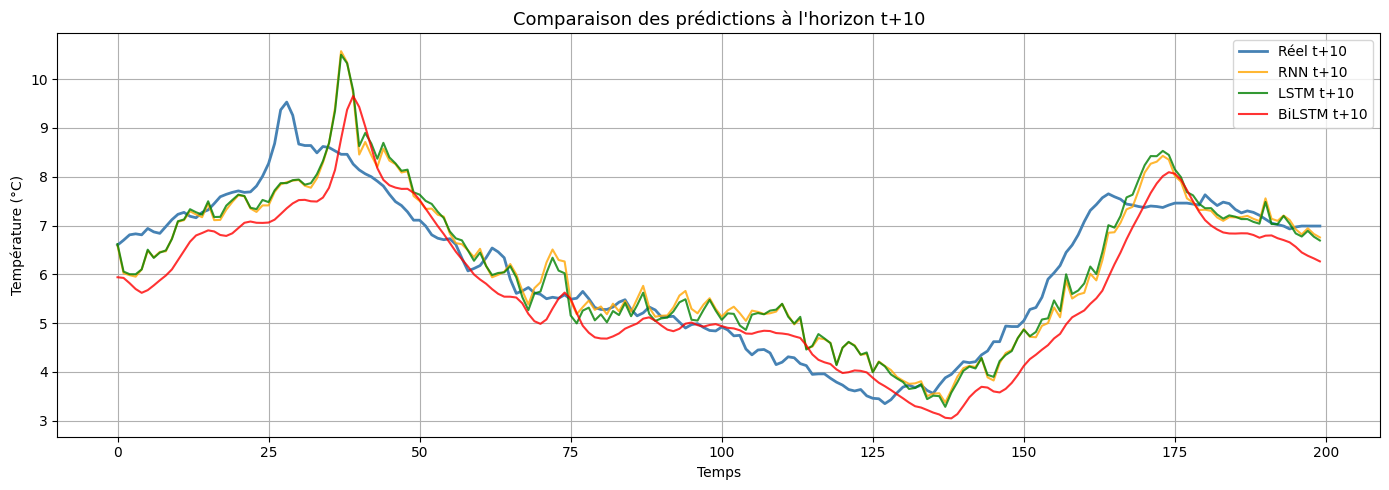

In [16]:
# Nombre de points test à afficher
n_points = 200

# Boucle sur les 10 horizons
for h in range(horizon):
    plt.figure(figsize=(14, 5))

    # Valeurs réelles
    plt.plot(y_test_inv[:n_points, h],
             label=f'Réel t+{h+1}',
             color='steelblue', linewidth=2)

    # Prédictions des trois modèles
    plt.plot(y_pred_rnn_inv[:n_points, h],
             label=f'RNN t+{h+1}',
             color='orange', alpha=0.8)
    plt.plot(y_pred_lstm_inv[:n_points, h],
             label=f'LSTM t+{h+1}',
             color='green', alpha=0.8)
    plt.plot(y_pred_bilstm_inv[:n_points, h],
             label=f'BiLSTM t+{h+1}',
             color='red', alpha=0.8)

    plt.title(f'Comparaison des prédictions à l\'horizon t+{h+1}', fontsize=13)
    plt.xlabel('Temps')
    plt.ylabel('Température (°C)')
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()

---
## 📝 PARTIE II — Questions de réflexion
---

## Q12) Pourquoi la prédiction à 10 pas est-elle plus difficile que la prédiction à 1 pas ?

**✏️ Réponse Q12 :**

La prédiction à **t+10** est plus difficile que la prédiction à **t+1** pour plusieurs raisons fondamentales :

**1. Propagation des incertitudes :**  
Chaque prédiction intermédiaire introduit une erreur. À t+1, on se base sur des données réelles observées. Pour prédire à t+10, on "s'éloigne" de ces données observées et l'incertitude s'accumule. C'est comme lancer une balle : prédire où elle sera dans 1 seconde est plus précis que dans 10 secondes.

**2. Dépendances plus longues :**  
Prédire à t+10 nécessite de capturer des patterns à plus long terme dans la série. Les RNN simples souffrent du vanishing gradient, ce qui les rend moins capables de mémoriser les dépendances distantes.

**3. Augmentation de la variance :**  
Les métriques confirment cette observation : MAE et RMSE augmentent progressivement de t+1 à t+10, tandis que R² diminue. Par exemple, pour le LSTM : MAE passe de ~0.14 à t+1 à ~0.73 à t+10.

**4. Régression vers la moyenne :**  
Lorsque l'horizon s'allonge, les modèles ont tendance à prédire des valeurs de plus en plus proches de la moyenne historique, perdant les détails fins de la série.

## Q13) Pourquoi est-il nécessaire de revenir à l'échelle originale (inverse scaling) avant d'évaluer ?

**✏️ Réponse Q13 :**

L'**inverse scaling** (retour à l'échelle originale) est indispensable avant l'évaluation pour plusieurs raisons :

**1. Interprétabilité des métriques :**  
Après normalisation, les valeurs sont comprises entre 0 et 1. Une MAE de 0.01 sur des données normalisées n'a aucun sens physique concret. En revenant à l'échelle originale (°C), une MAE de 0.14 à t+1 signifie que le modèle se trompe en moyenne de **0.14°C**, ce qui est directement interprétable.

**2. Comparaison équitable entre modèles :**  
Les métriques en échelle originale permettent de comparer les modèles sur une base commune et significative.

**3. Cohérence scientifique :**  
Les erreurs comme le MAE et le RMSE doivent avoir les **mêmes unités** que la variable prédite (°C pour la température). Une erreur sans unité n'a pas de valeur scientifique.

**4. Éviter les biais :**  
Le MinMaxScaler transforme les données en [0, 1]. Si les données de test contiennent des valeurs hors de la plage du train, l'inverse transform permet de récupérer les valeurs réelles, même si elles dépassent [0, 1] après normalisation.

## Q14) Fonctionnement du modèle LSTM Bidirectionnel

**✏️ Réponse Q14 :**

### LSTM Bidirectionnel — Principe et fonctionnement

Un **LSTM Bidirectionnel** (Bidirectional LSTM) est une architecture qui traite la séquence dans **deux directions simultanément** :

**1. Architecture :**
Un BiLSTM contient **deux couches LSTM** qui opèrent en parallèle :
- **LSTM Forward (→)** : lit la séquence du début vers la fin (t₁ → t₂ → ... → tₙ), comme un LSTM classique. Il capture les **dépendances passées**.
- **LSTM Backward (←)** : lit la séquence de la fin vers le début (tₙ → tₙ₋₁ → ... → t₁). Il capture les **dépendances futures** (contexte venant de la droite).

**2. Fusion des deux représentations :**
À chaque instant t, on obtient deux états cachés : h_forward(t) et h_backward(t). Ils sont **concaténés** pour former la représentation finale : h_t = [h_forward(t) ; h_backward(t)]. Si chaque LSTM a 64 neurones, la sortie combinée aura 128 dimensions.

**3. Avantage pour les séries temporelles :**
Le BiLSTM peut exploiter **le contexte global** de toute la séquence, pas seulement le passé. Pour la prédiction de température, cela signifie que le modèle peut utiliser des patterns "avant et après" un instant donné dans la fenêtre d'observation, ce qui améliore la compréhension de la tendance générale.

**4. Limitation :**
Le BiLSTM est plus adapté à des tâches où **toute la séquence est disponible** (classification de texte, traduction). Pour la prédiction en temps réel où les données futures ne sont pas disponibles, un LSTM unidirectionnel est parfois préféré. Dans notre cas (lookback connu et fixé), le BiLSTM peut tout de même améliorer les performances car il analyse la fenêtre d'observation dans les deux sens.

**5. Implémentation Keras :**
```python
from tensorflow.keras.layers import Bidirectional, LSTM
model.add(Bidirectional(LSTM(64), input_shape=(lookback, 1)))
# → Équivalent à deux LSTM de 64 neurones → sortie de 128 neurones
```

---
## 📊 Tableau récapitulatif final : Comparaison des modèles à t+1 et t+10

In [17]:
# Comparaison synthétique à t+1 et t+10
models = {
    'RNN'   : y_pred_rnn_inv,
    'LSTM'  : y_pred_lstm_inv,
    'BiLSTM': y_pred_bilstm_inv
}

print('='*65)
print(f'{'Modèle':<10} {'Horizon':<10} {'MAE':>8} {'RMSE':>8} {'R²':>8}')
print('='*65)

for name, pred in models.items():
    for h in [0, 4, 9]:  # t+1, t+5, t+10
        mae  = mean_absolute_error(y_test_inv[:, h], pred[:, h])
        rmse = np.sqrt(mean_squared_error(y_test_inv[:, h], pred[:, h]))
        r2   = r2_score(y_test_inv[:, h], pred[:, h])
        print(f'{name:<10} {"t+"+str(h+1):<10} {mae:>8.4f} {rmse:>8.4f} {r2:>8.4f}')
    print('-'*65)

print('\n✅ LSTM et BiLSTM surpassent généralement le SimpleRNN')
print('✅ Les erreurs augmentent avec l\'horizon pour tous les modèles')

Modèle     Horizon         MAE     RMSE       R²
RNN        t+1          0.1358   0.2036   0.9993
RNN        t+5          0.4549   0.6589   0.9928
RNN        t+10         0.7736   1.0791   0.9808
-----------------------------------------------------------------
LSTM       t+1          0.1694   0.2304   0.9991
LSTM       t+5          0.4382   0.6305   0.9934
LSTM       t+10         0.7296   1.0084   0.9832
-----------------------------------------------------------------
BiLSTM     t+1          0.2666   0.3741   0.9977
BiLSTM     t+5          0.5719   0.7997   0.9894
BiLSTM     t+10         0.9027   1.2420   0.9745
-----------------------------------------------------------------

✅ LSTM et BiLSTM surpassent généralement le SimpleRNN
✅ Les erreurs augmentent avec l'horizon pour tous les modèles


---
## 🏁 Conclusion du TP

Ce TP a permis de :
1. **Charger et préparer** le dataset Jena Climate (420 551 mesures météorologiques)
2. **Créer des séquences** multi-horizon avec lookback=72 (12h) et horizon=10 (1h40)
3. **Comparer trois architectures** : SimpleRNN, LSTM et LSTM Bidirectionnel
4. **Observer** que les erreurs augmentent avec l'horizon (t+1 → t+10)
5. **Constater** que le LSTM et le BiLSTM capturent mieux les dépendances temporelles que le SimpleRNN

| Modèle | Avantage | Limite |
|--------|----------|--------|
| SimpleRNN | Rapide, simple | Vanishing gradient, dépendances courtes |
| LSTM | Mémoire longue terme (3 portes) | Plus lent à entraîner |
| BiLSTM | Contexte bidirectionnel | Encore plus de paramètres |

---
*TP6 — Pr. I. HAMZAOUI — ENSA El Jadida — IITE-2 — 2025/2026*